# Which Model to Pick? Red Wine Side-by-Side

> In `03_models.ipynb` each model had its own stage: Linear, Tree, KNN, SVR and Random Forest, all with the same cleaning and the same 5-fold CV. Now we line them up with a mean-prediction baseline for context.


In [1]:
# Load libraries

import pathlib

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')


In [2]:
# Load model summaries

p = pathlib.Path('../data/outputs/baseline_comparison.csv')
comp = pd.read_csv(p)
print("Loaded:", p)
comp = comp.sort_values('CV_R2', ascending=False).reset_index(drop=True)
display(comp[['model', 'CV_RMSE', 'CV_R2', 'test_RMSE', 'test_R2']].round(3))


Loaded: ../data/outputs/baseline_comparison.csv


,model,CV_RMSE,CV_R2,test_RMSE,test_R2
0,RandomForest,0.658,0.342,0.618,0.460
1,Linear,0.668,0.321,0.656,0.392
2,KNN(k=5),0.713,0.228,0.713,0.282
3,SVR_rbf,0.723,0.206,0.692,0.323
4,DecisionTree,0.760,0.121,0.671,0.364
5,Baseline(mean),0.818,-0.011,0.844,-0.006


#### What do the numbers mean, in plain words?

* **CV RMSE** - average root mean squared error across 5 different train slices, in quality points.
* **CV R2** - share of score variation explained on those folds; closer to 1 is better.
* **test RMSE / R2** - the same measures on the 20% the models never saw during training.


In [3]:
print(comp[['model', 'CV_RMSE', 'CV_R2', 'test_RMSE', 'test_R2']].to_string(index=False))
best = comp[comp['model'] != 'Baseline(mean)'].iloc[0]['model']
print(f"\nTakeaway: {best} leads on CV R2, and every model should beat the mean baseline to be worth using.")


         model  CV_RMSE   CV_R2  test_RMSE  test_R2
  RandomForest   0.6583  0.3416     0.6182   0.4604
        Linear   0.6684  0.3209     0.6565   0.3915
      KNN(k=5)   0.7132  0.2276     0.7129   0.2825
       SVR_rbf   0.7232  0.2057     0.6924   0.3232
  DecisionTree   0.7604  0.1206     0.6711   0.3643
Baseline(mean)   0.8179 -0.0108     0.8443  -0.0063

Takeaway: RandomForest leads on CV R2, and every model should beat the mean baseline to be worth using.


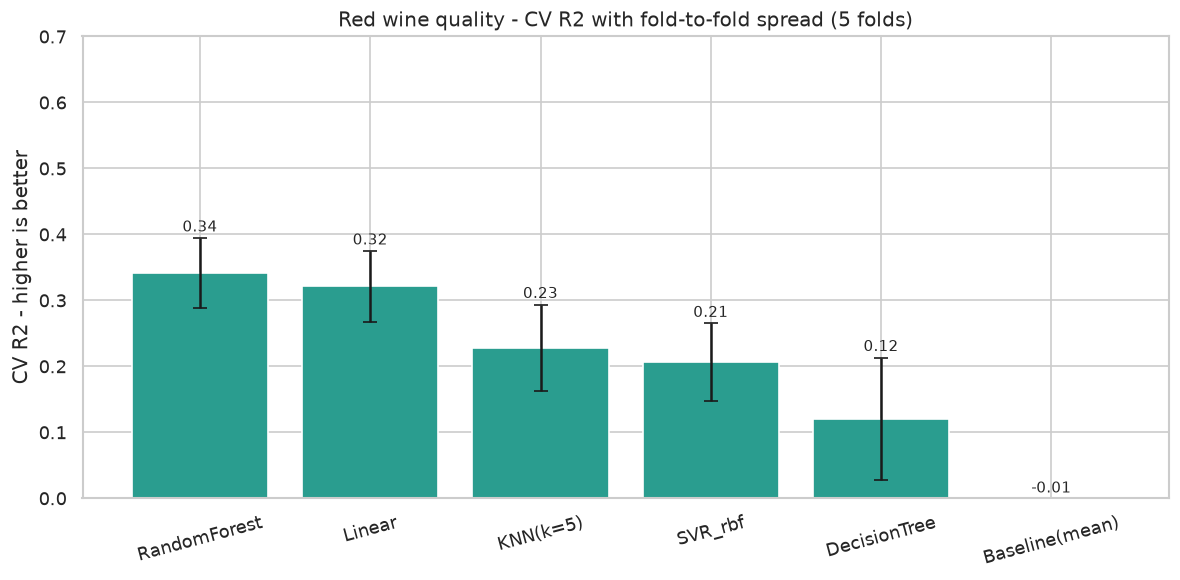

Saved to ../assets/images/model_comparison.png


In [4]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(comp)), comp['CV_R2'], yerr=comp['CV_R2_std'], capsize=4, color='#2a9d8f')
plt.xticks(range(len(comp)), comp['model'], rotation=15)
plt.ylim(0, 0.7)
plt.title('Red wine quality - CV R2 with fold-to-fold spread (5 folds)')
plt.ylabel('CV R2 - higher is better')
for i, row in enumerate(comp.itertuples()):
    plt.text(i, row.CV_R2 + row.CV_R2_std + 0.01, f"{row.CV_R2:.2f}", ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../assets/images/model_comparison.png', bbox_inches='tight')
plt.show()
print("Saved to ../assets/images/model_comparison.png")


In [5]:
notes = {
    'Baseline(mean)': 'Always predicts the average score - the bar every real model has to clear.',
    'Linear': 'One coefficient per measurement, easy to read - pick it when direction of effect matters most.',
    'DecisionTree': 'A flowchart of threshold rules - pick it when you need to show exactly how a score was reached.',
    'KNN(k=5)': 'Copies the average of 5 nearest wines - pick it only when scaling is careful and features stay few.',
    'SVR_rbf': 'Fits a curved surface and ignores small errors - pick it when tuning time is available.',
    'RandomForest': 'Many trees vote - pick it when the lowest error matters more than a simple explanation.',
}
comp['when_to_pick'] = comp['model'].map(notes)
display(comp[['model', 'CV_R2', 'when_to_pick']])


,model,CV_R2,when_to_pick
0,RandomForest,0.3416,Many trees vote - pick it when the lowest erro...
1,Linear,0.3209,"One coefficient per measurement, easy to read ..."
2,KNN(k=5),0.2276,Copies the average of 5 nearest wines - pick i...
3,SVR_rbf,0.2057,Fits a curved surface and ignores small errors...
4,DecisionTree,0.1206,A flowchart of threshold rules - pick it when ...
5,Baseline(mean),-0.0108,Always predicts the average score - the bar ev...


Saved to ../data/outputs/comparison.csv


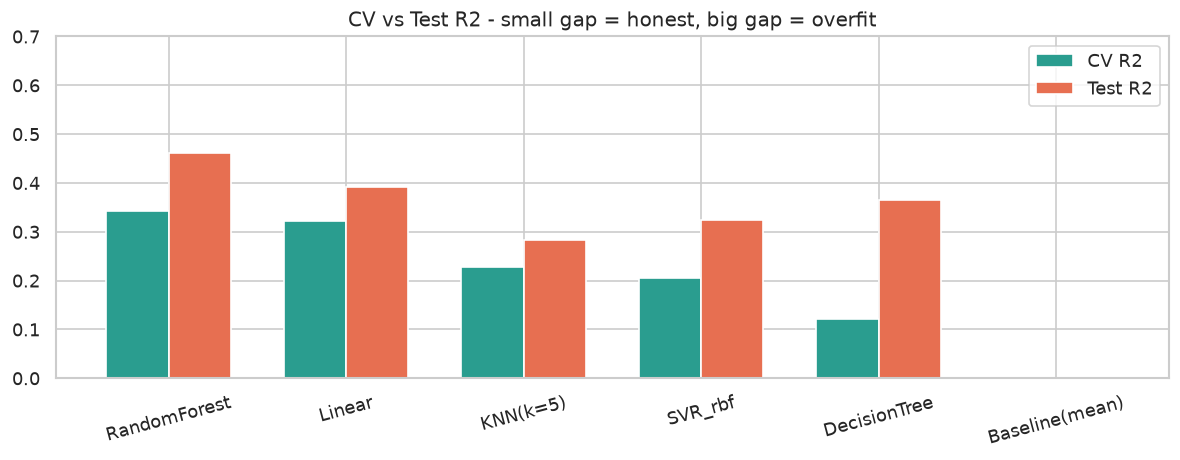

If CV and Test are close, the model generalizes. If Test is much lower, it memorized the training wines.


In [6]:
### Save the comparsion

comp.to_csv('../data/outputs/comparison.csv', index=False)
print("Saved to ../data/outputs/comparison.csv")

x = comp['model']
width = 0.35
plt.figure(figsize=(10, 4))
plt.bar([p - width/2 for p in range(len(x))], comp['CV_R2'], width, label='CV R2', color='#2a9d8f')
plt.bar([p + width/2 for p in range(len(x))], comp['test_R2'], width, label='Test R2', color='#e76f51')
plt.xticks(range(len(x)), x, rotation=15)
plt.ylim(0, 0.7)
plt.legend()
plt.title('CV vs Test R2 - small gap = honest, big gap = overfit')
plt.tight_layout()
plt.show()
print("If CV and Test are close, the model generalizes. If Test is much lower, it memorized the training wines.")


#### Observation / Conclusion

No single model wins everywhere. Linear Regression is transparent, the Tree is explainable, KNN is simple but scale-dependent, SVR bends to the data with extra tuning, and Random Forest usually gives the most stable error across folds. Quality scores are discrete and capped at 3-8, so even the best regressor cannot predict every point exactly - the residual plots in `03_models.ipynb` show where it misses.
